In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("IPL.csv")

df.head()


,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,second_ings_score,second_ings_wkts,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure
0,1,"March 26,2022","Wankhede Stadium, Mumbai",Chennai,Kolkata,Group,Kolkata,Field,131,5,133,4,Kolkata,Wickets,6,Umesh Yadav,MS Dhoni,50,Dwayne Bravo,3--20
1,2,"March 27,2022","Brabourne Stadium, Mumbai",Delhi,Mumbai,Group,Delhi,Field,177,5,179,6,Delhi,Wickets,4,Kuldeep Yadav,Ishan Kishan,81,Kuldeep Yadav,3--18
2,3,"March 27,2022","Dr DY Patil Sports Academy, Mumbai",Banglore,Punjab,Group,Punjab,Field,205,2,208,5,Punjab,Wickets,5,Odean Smith,Faf du Plessis,88,Mohammed Siraj,2--59
3,4,"March 28,2022","Wankhede Stadium, Mumbai",Gujarat,Lucknow,Group,Gujarat,Field,158,6,161,5,Gujarat,Wickets,5,Mohammed Shami,Deepak Hooda,55,Mohammed Shami,3--25
4,5,"March 29,2022","Maharashtra Cricket Association Stadium,Pune",Hyderabad,Rajasthan,Group,Hyderabad,Field,210,6,149,7,Rajasthan,Runs,61,Sanju Samson,Aiden Markram,57,Yuzvendra Chahal,3--22


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   match_id             74 non-null     int64 
 1   date                 74 non-null     object
 2   venue                74 non-null     object
 3   team1                74 non-null     object
 4   team2                74 non-null     object
 5   stage                74 non-null     object
 6   toss_winner          74 non-null     object
 7   toss_decision        74 non-null     object
 8   first_ings_score     74 non-null     int64 
 9   first_ings_wkts      74 non-null     int64 
 10  second_ings_score    74 non-null     int64 
 11  second_ings_wkts     74 non-null     int64 
 12  match_winner         74 non-null     object
 13  won_by               74 non-null     object
 14  margin               74 non-null     int64 
 15  player_of_the_match  74 non-null     object
 16  top_scorer

In [5]:
df.isnull().sum()

match_id               0
date                   0
venue                  0
team1                  0
team2                  0
stage                  0
toss_winner            0
toss_decision          0
first_ings_score       0
first_ings_wkts        0
second_ings_score      0
second_ings_wkts       0
match_winner           0
won_by                 0
margin                 0
player_of_the_match    0
top_scorer             0
highscore              0
best_bowling           0
best_bowling_figure    0
dtype: int64

In [6]:
print(f'All Rows Are {df.shape[0]} & All Columns Are {df.shape[1]}')

All Rows Are 74 & All Columns Are 20


In [7]:
match_wins = df['match_winner'].value_counts()

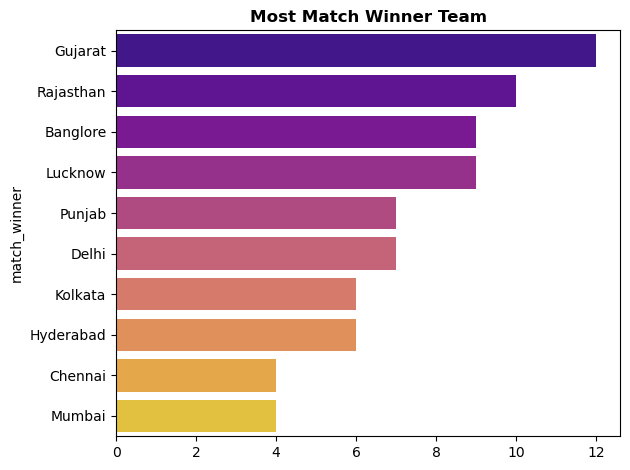

In [24]:
sns.barplot(y = match_wins.index , x = match_wins.values, palette = 'plasma')
plt.title('Most Match Winner Team', fontweight = 'bold')
plt.tight_layout()
plt.savefig('Most Match winner Team.jpg', dpi = 150, bbox_inches = 'tight')

Text(0.5, 1.0, 'Toss Decisions')

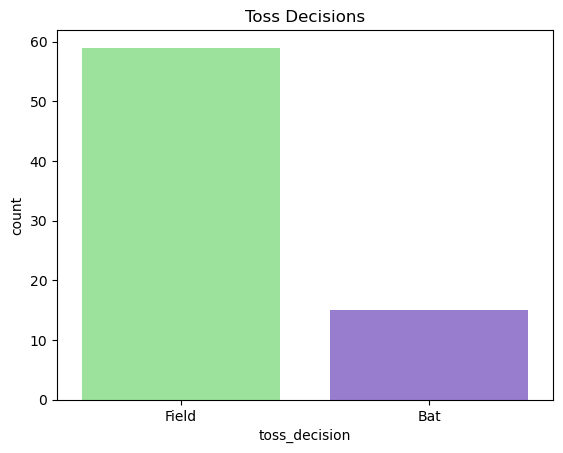

In [9]:
sns.countplot(x = df['toss_decision'], palette = ['lightgreen','mediumpurple'])
plt.title('Toss Decisions')

In [10]:
count = df[df['toss_winner']== df['match_winner']]['match_id'].count()
percentage = (count * 100)/df.shape[0]
print(f'If Won Toss, {percentage.round(2)}% Is Chance To Win Match')

If Won Toss, 48.65% Is Chance To Win Match


Text(0.5, 1.0, 'Won By')

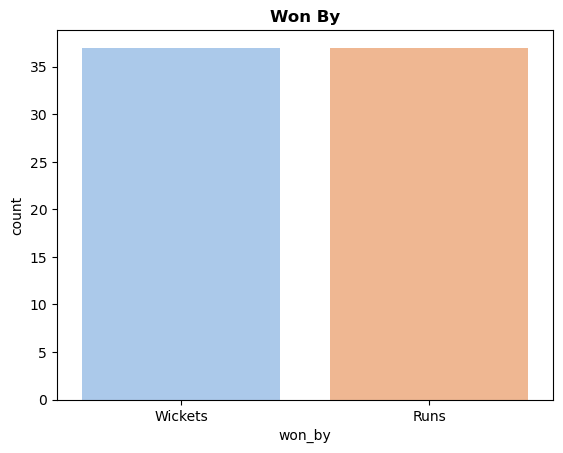

In [11]:
sns.countplot(x = df['won_by'], palette = 'pastel')
plt.title('Won By', fontweight = 'bold')

In [12]:
count = df['player_of_the_match'].value_counts().head(20)

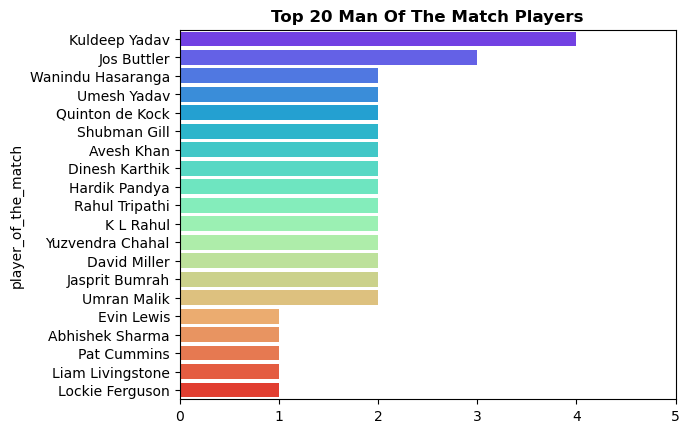

In [13]:
sns.barplot(y = count.index, x = count.values, palette = 'rainbow')
plt.title('Top 20 Man Of The Match Players', fontweight = 'bold')
plt.xticks([0,1,2,3,4,5])
plt.show()

In [14]:
high = df.groupby('top_scorer')['highscore'].sum().sort_values(ascending = False).head(3)

Text(0.5, 1.0, 'Top 3 Most Runs Scorers')

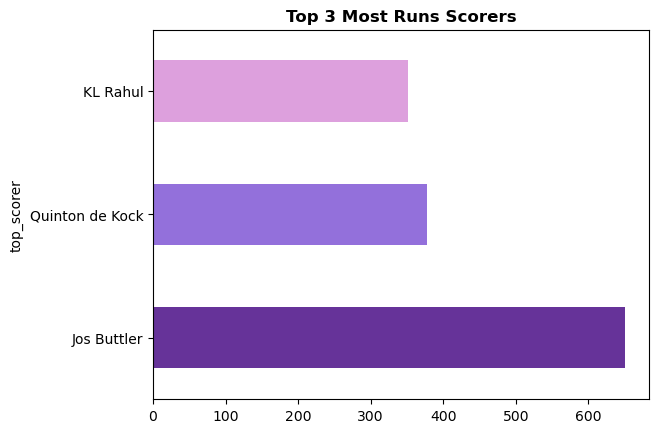

In [15]:
high.plot(kind = 'barh',color = ['rebeccapurple', 'mediumpurple', 'plum'])
plt.title('Top 3 Most Runs Scorers', fontweight = 'bold')

Text(0.5, 1.0, 'Top 10 Highest Wicket Tacker Bowlers')

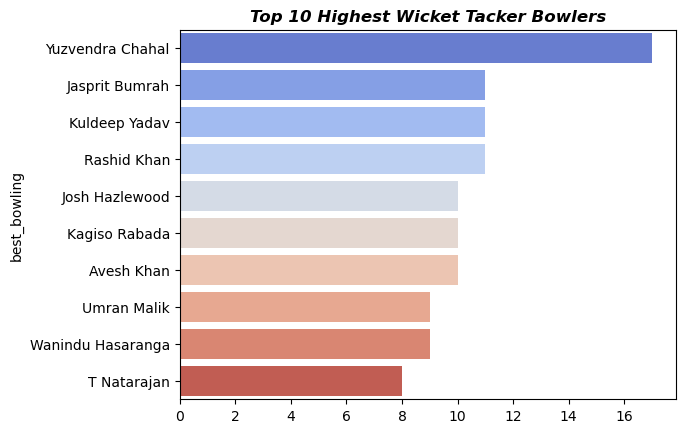

In [16]:
df['highest_wickets'] = df['best_bowling_figure'].apply(lambda x: x.split('--')[0])
df['highest_wickets'] = df['highest_wickets'].astype(int)
top_bowlers = df.groupby('best_bowling')['highest_wickets'].sum().sort_values(ascending = False).head(10)

sns.barplot(x=top_bowlers.values, y=top_bowlers.index, palette='coolwarm')
plt.title('Top 10 Highest Wicket Tacker Bowlers', fontweight = 'bold', style ='italic')

In [17]:
df[df['highscore'] == df['highscore'].max()][['top_scorer','highscore']]

,top_scorer,highscore
65,Quinton de Kock,140


In [18]:
venue_counts = df['venue'].value_counts()
venue_counts

venue
Wankhede Stadium, Mumbai                        21
Dr DY Patil Sports Academy, Mumbai              20
Brabourne Stadium, Mumbai                       16
Maharashtra Cricket Association Stadium,Pune    13
Eden Gardens, Kolkata                            2
Narendra Modi Stadium, Ahmedabad                 2
Name: count, dtype: int64

Text(0.5, 1.0, 'Most Match Played Venue')

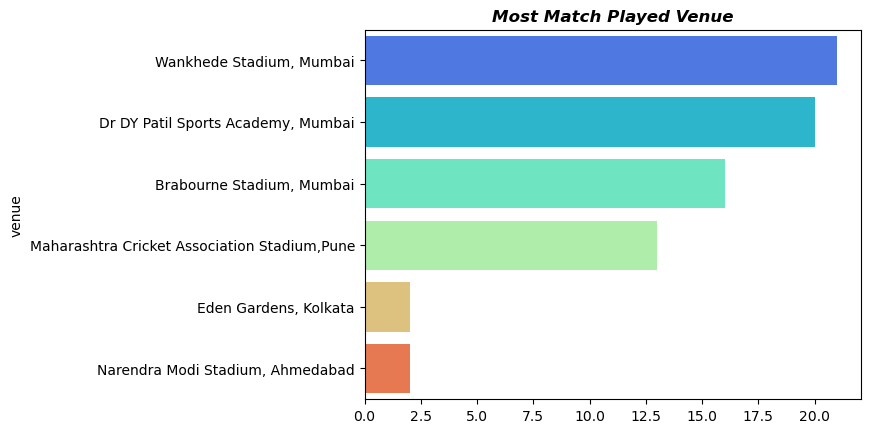

In [19]:
sns.barplot(y = venue_counts.index, x = venue_counts.values, palette = 'rainbow')
plt.title('Most Match Played Venue', fontweight = 'bold', style = 'italic')